# ADP 모의고사 2회 상황형 연습 - 풀이

**상황형 재구성 연습·예시 풀이이며 공식 원문/정답이 아닙니다.**

출처: 모의고사 2.ipynb

원 자료 조건: 원 데이터가 첨부되지 않아 동일 컬럼·분석 주제의 합성 연습 자료를 제공합니다. 수치 정답은 원 시험과 다릅니다.

문제는 동봉 상황형 문제지와 같습니다. 원문은 문항목록.json·추가_문항명세.json에 보존합니다. 순서대로 실행하며 각 대문항에서 고정한 자료·전처리·분할을 후속 문항에 재사용합니다. 통계 답안은 선정 근거 → 가정·가설 → 통계량·p-value → 기각 여부·상황 해석 순서로 작성합니다. 확률·구간 추정·관리도 문항에 불필요한 귀무가설을 만들지 않습니다.

실행: 해당 회차 폴더에서 위에서 아래로 실행합니다. 가설검정_답안.json은 실제 계산한 가설·수치·결론 기록입니다.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.svm import SVC
from IPython.display import display
# repository root 또는 회차 폴더에서 탐색; 경로를 하드코딩하지 않음.
ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/reconstruction.py').exists())
sys.path.insert(0,str(ROOT));sys.path.insert(0,str(ROOT/'기출문제/공통'))
from reconstruction import *
from matplotlib import font_manager
font_path=ROOT/'기출문제/공통/NanumGothic-Regular.ttf'
font_manager.fontManager.addfont(str(font_path))
plt.rcParams['font.family']='NanumGothic';plt.rcParams['axes.unicode_minus']=False
HERE=ROOT/'기출문제'/'모의고사/2회';DATA=HERE/'data';OUT=HERE/'실행결과';OUT.mkdir(exist_ok=True)
def load(name):return pd.read_csv(DATA/name)
print('데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님')

# 상황형 답안 기록 초기화
_SCENARIO_ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/scenario_inference.py').is_file())
sys.path.insert(0,str(_SCENARIO_ROOT/'기출문제/공통'))
from scenario_inference import (reset_reports, set_question, report_test, report_anova,
    report_correlations, report_adf, report_residuals, report_regression_diagnostics)
reset_reports(OUT)


데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님


## 1. 입학 허가 수준 설명

입학 상담팀은 독립 지원자 자료에서 Chance_of_Admit와 지원 특성의 관계를 설명하려 한다. 연속 변수 간 선형 관계를 우선 살피되 관계가 인과 효과라는 보장은 없다.

자료: Admission.csv

### 1-1

입학 허가 수준과 GRE·TOEFL·Univ_Rating·SOP·LOR·CGPA의 관계를 수치·그림으로 평가하시오. 관계 평가 방법과 가정을 선택하고 각 관계의 귀무·대립가설, p-value·기각 여부를 제시하시오. 다중 탐색의 한계도 설명하시오.

**판단 및 풀이 근거**

연속 변수의 선형 관계를 Pearson으로 평가한다. 각 H0: rho=0, H1: rho≠0이며 상관 크기와 Holm 보정 p값을 구분한다. 명목 범주 코드에 수치 간격 의미를 부여하지 않는다.

**계산·해석 상세**

선형 관계의 방향·크기를 r로, H0:rho=0의 증거를 p값으로 구분합니다. 다수 상관 검정은 탐색으로 보고합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 가설·통계량·p-value·기각 여부·상황 결론을 함께 출력하며 수치는 실행 결과에 따라 결정합니다.

    feature         r      p_value
        GRE  0.577492 9.563125e-23
      TOEFL  0.528240 1.195124e-18
Univ_Rating  0.081874 2.062708e-01
        SOP -0.059005 3.627578e-01
        LOR  0.108662 9.304003e-02
       CGPA  0.836827 3.303858e-64


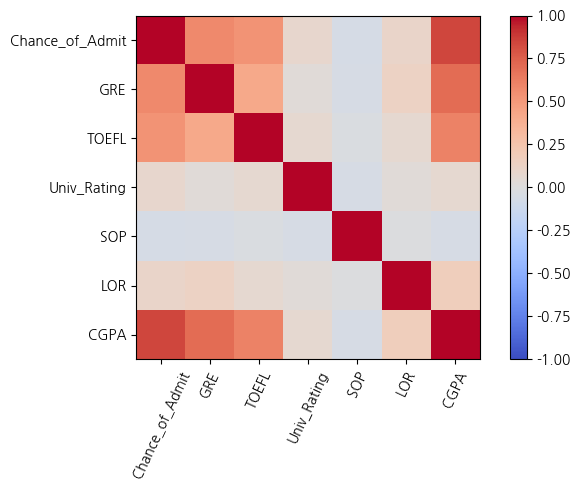

{
  "question": "1-1",
  "method": "Pearson 선형 상관: GRE",
  "H0": "rho(Chance_of_Admit,GRE)=0",
  "H1": "rho(Chance_of_Admit,GRE) != 0",
  "statistic": 0.5774915012910937,
  "p_value": 9.563124903236728e-23,
  "alpha": 0.05,
  "reject_H0": true,
  "assumptions": "독립 관측·선형 관계·이변량 정규 추론, 이상값 점검. 다중 비교 Holm 보정; 인과가 아님.",
  "conclusion": "귀무가설을 기각한다. Chance_of_Admit와 GRE 사이에 선형 관계가 있다는 통계적 근거가 있다.",
  "adjusted_p_value": 4.781562451618364e-22,
  "decision_basis": "Holm 보정 p값"
}
{
  "question": "1-1",
  "method": "Pearson 선형 상관: TOEFL",
  "H0": "rho(Chance_of_Admit,TOEFL)=0",
  "H1": "rho(Chance_of_Admit,TOEFL) != 0",
  "statistic": 0.5282400368607214,
  "p_value": 1.1951240651199552e-18,
  "alpha": 0.05,
  "reject_H0": true,
  "assumptions": "독립 관측·선형 관계·이변량 정규 추론, 이상값 점검. 다중 비교 Holm 보정; 인과가 아님.",
  "conclusion": "귀무가설을 기각한다. Chance_of_Admit와 TOEFL 사이에 선형 관계가 있다는 통계적 근거가 있다.",
  "adjusted_p_value": 4.780496260479821e-18,
  "decision_basis": "Holm 보정 p값"
}
{
  "question": "1-1",
  "method": 

In [2]:
set_question('1-1')
admit=load('Admission.csv');numeric_correlations(admit,'Chance_of_Admit',['GRE','TOEFL','Univ_Rating','SOP','LOR','CGPA'])

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
report_correlations(admit,'Chance_of_Admit',['GRE', 'TOEFL', 'Univ_Rating', 'SOP', 'LOR', 'CGPA'])

### 1-2

앞 특성과 Research를 후보로 입학 허가 수준의 설명 모형을 구성하시오. 변수 추가·제거 기준, 추정식·잔차 점검과 선택 후 해석의 한계를 제시하시오.

**판단 및 풀이 근거**

AIC 선택 후 잔차의 정규성·등분산을 진단한다. 선택 후 계수 p값은 탐색적이며 전체 선택 절차를 무시한 확증 근거로 쓰지 않는다.

**계산·해석 상세**

원문 Shapiro p=.09를 기각으로 해석한 오류를 수정합니다. p>=.05에서는 정규성 귀무가설을 기각하지 못합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 가설·통계량·p-value·기각 여부·상황 결론을 함께 출력하며 수치는 실행 결과에 따라 결정합니다.

선택 변수: ['CGPA']
   step features         AIC
0     1     CGPA -722.230836
                            OLS Regression Results                            
Dep. Variable:        Chance_of_Admit   R-squared:                       0.700
Model:                            OLS   Adj. R-squared:                  0.699
Method:                 Least Squares   F-statistic:                     556.1
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           3.30e-64
Time:                        09:51:49   Log-Likelihood:                 363.12
No. Observations:                 240   AIC:                            -722.2
Df Residuals:                     238   BIC:                            -715.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

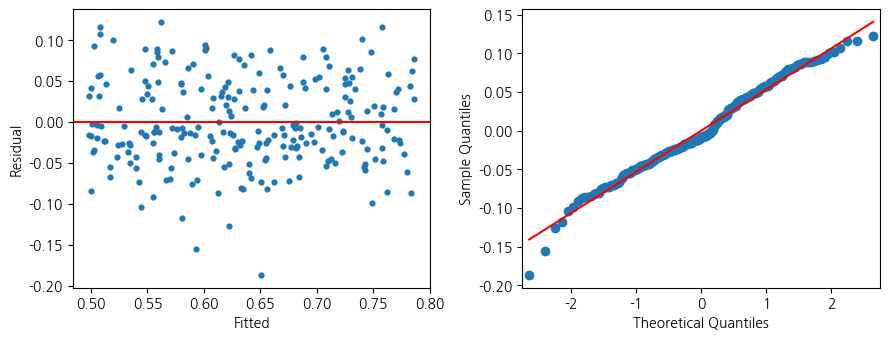

{
  "question": "1-2",
  "method": "Shapiro-Wilk 잔차 진단",
  "H0": "잔차 분포가 정규이다",
  "H1": "잔차 분포가 정규가 아니다",
  "statistic": 0.9857776876905664,
  "p_value": 0.01713639608620014,
  "alpha": 0.05,
  "reject_H0": true,
  "assumptions": "선택된 모형의 잔차를 이용한 탐색 진단이며 선택 후 추론의 한계가 있다.",
  "conclusion": "귀무가설을 기각한다. 잔차 분포가 정규에서 벗어난다는 통계적 근거가 있다."
}
{
  "question": "1-2",
  "method": "Breusch-Pagan 잔차 진단",
  "H0": "오차 분산이 일정하다",
  "H1": "오차 분산이 일정하지 않다",
  "statistic": 0.9882120722145071,
  "p_value": 0.3201797526134328,
  "alpha": 0.05,
  "reject_H0": false,
  "assumptions": "독립 관측과 지정된 분산 설명 구조에 의존하는 점근적 진단이다.",
  "conclusion": "귀무가설을 기각하지 못한다. 잔차에 이분산이 존재한다는 통계적 근거가 충분하지 않다. 귀무가설의 참을 입증한 것은 아니다.",
  "df": 1
}


In [3]:
set_question('1-2')
admit_model=select_ols(admit,'Chance_of_Admit',['GRE','TOEFL','Univ_Rating','SOP','LOR','CGPA','Research'],'stepwise');residual_diagnostics(admit_model)

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
report_regression_diagnostics(admit_model)

## 2. 승객 생존 예측

별도 승객 자료로 survived를 예측하려 한다. 이 대문항의 전처리와 모든 비교는 같은 7:3 분할·시드 12345를 사용한다. pclass·sex·sibsp·parch·fare·embarked를 예측 특성으로 사용한다.

자료: titanic.csv

### 2-1

빈 문자열·변수 자료형·결측을 점검하시오. 수치형 중앙값·범주형 최빈값 대치와 연령 10세 구간 age_1(0~8)을 구성하되 대치 기준은 학습 자료에서만 구하시오. 범위 밖 연령을 점검하시오.

**판단 및 풀이 근거**

문제의 전처리 완료 후 분할 순서를 그대로 쓰면 test 정보가 대치값에 들어갑니다. 빈문자·타입·구간은 유지하고 통계량 적합은 학습으로 한정합니다. 실제 분류 입력의 대치는 Pipeline에서 수행합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [4]:
set_question('2-1')
titanic=load('titanic.csv').replace('',np.nan)
titanic['pclass']=titanic.pclass.astype('category');titanic['sex']=titanic.sex.astype('category')
ids_train,ids_test=train_test_split(np.arange(len(titanic)),test_size=.3,random_state=12345,stratify=titanic.survived)
median_age=titanic.iloc[ids_train].age.median();titanic['age_imputed']=titanic.age.fillna(median_age)
titanic['age_1']=pd.cut(titanic.age_imputed,bins=list(range(0,91,10)),labels=list(range(9)),right=False)
print(titanic[['age','age_imputed','age_1']].head());print('train age median:',median_age)

         age  age_imputed age_1
0  68.153239    68.153239     6
1  15.791815    15.791815     1
2  37.333111    37.333111     3
3  65.214912    65.214912     6
4  45.493908    45.493908     4
train age median: 43.11805070558041


### 2-2

고정한 분할로 서로 다른 분류 모형 3개 이상을 적합하시오. 각 모형의 시험 예측 CSV를 제출하고 전처리·비교 조건이 일치함을 확인하시오.

**판단 및 풀이 근거**

R set.seed와 NumPy random_state는 같은 난수열을 보장하지 않습니다. Python 재현 시드만 12345로 유지합니다. Logistic/RF/GradientBoosting 세 모델의 동일 보류 예측 CSV를 저장합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

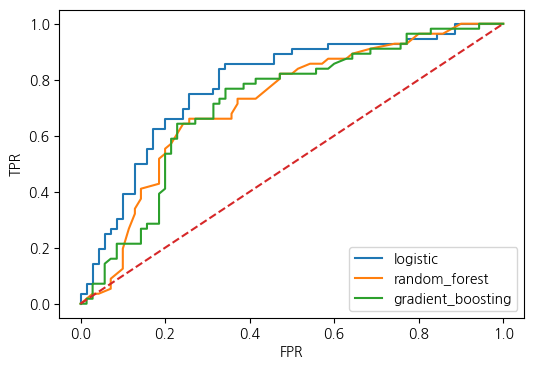

               model  accuracy  f1_weighted   ROC_AUC
0           logistic  0.722222     0.723011  0.783418
1      random_forest  0.706349     0.706068  0.717857
2  gradient_boosting  0.698413     0.698413  0.715434


In [5]:
set_question('2-2')
titanic_scores,titanic_models,train,test=classify(titanic,'survived',['pclass','sex','sibsp','parch','fare','embarked'],OUT,seed=12345)

### 2-3

같은 시험 자료에서 정확도와 ROC-AUC·ROC 곡선을 비교하시오. 양성 확률의 필요성과 이 자료로 다시 튜닝할 때의 문제를 설명하시오.

**판단 및 풀이 근거**

ROC는 이산 클래스가 아니라 predict_proba의 양성 확률로 계산했습니다. 위 셀의 동일 holdout 그래프와 AUC를 보고하며 test 최고를 새 튜닝의 근거로 쓰지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [6]:
set_question('2-3')
print(titanic_scores);print('보류 최고 accuracy 모델:',titanic_scores.loc[titanic_scores.accuracy.idxmax(),'model'])

               model  accuracy  f1_weighted   ROC_AUC
0           logistic  0.722222     0.723011  0.783418
1      random_forest  0.706349     0.706068  0.717857
2  gradient_boosting  0.698413     0.698413  0.715434
보류 최고 accuracy 모델: logistic


## 3. 연설문 관심 주제

별도의 합성 연설문과 명시 품사 사전이 주어진다. 문서별 맥락을 유지한 관심 단어 요약이 목적이다.

자료: speech.csv + lexicon.csv

### 3-1

숫자·특수문자를 정제하고 원문과 정제 문서의 대응을 확인하시오. 삭제로 손실될 수 있는 정보를 설명하시오.

**판단 및 풀이 근거**

문서별 구분을 유지해 숫자·특수 기호만 제거합니다. 합성 자료의 내용·빈도가 실제 취임사의 결과는 아닙니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [7]:
set_question('3-1')
speech=load('speech.csv');lexicon=load('lexicon.csv');speech['clean']=speech.text.map(clean_text);print(speech[['text','clean']].head())

                              text                     clean
0  공구 가족 민주주의 맛 민주주의 영화 빠르다 123 !@  공구 가족 민주주의 맛 민주주의 영화 빠르다
1      배송 여행 호텔 배송 여행 배송 좋다 123 !@      배송 여행 호텔 배송 여행 배송 좋다
2      가족 학교 행복 공구 호텔 공구 좋다 123 !@      가족 학교 행복 공구 호텔 공구 좋다
3   공구 공구 학교 민주주의 영화 여행 즐겁다 123 !@   공구 공구 학교 민주주의 영화 여행 즐겁다
4      배송 공구 배송 호텔 행복 공구 좋다 123 !@      배송 공구 배송 호텔 행복 공구 좋다


### 3-2(보충)

사전에서 명사로 지정된 어휘를 추출하고 빈도 상위 10개를 시각화하시오. 빈도 순위를 문서의 의미나 실제 여론으로 단정할 수 없는 이유를 설명하시오.

**판단 및 풀이 근거**

첨부 풀이 코드의 명사 추출·빈도 그래프에서 보충했습니다. 일반 원문 형태소 분석기 대체가 아닙니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

   word  count
0    학교     47
1    공구     40
2    호텔     39
3    행복     39
4  민주주의     35
5    영화     34
6    가족     33
7    배송     33
8    여행     33
9     맛     27


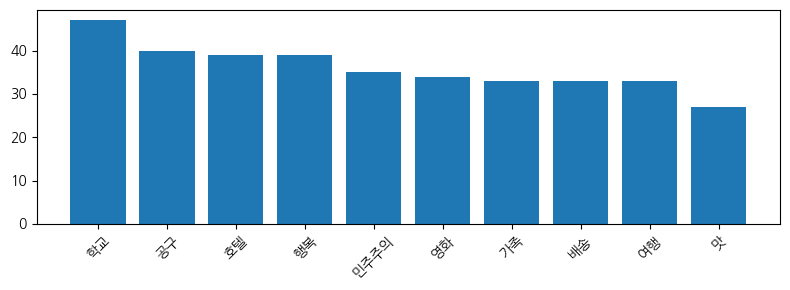

In [8]:
set_question('3-2(보충)')
word_plot(lexical_pos(speech.text,lexicon),10)